<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Native dependency and setup](README.md)

# 01 · Normalized address candidates are not confirmed duplicates

Abbreviations and spelling variants can hide similar address records. Normalization can also bring different apartments in the same building together. We will parse synthetic records, build conservative candidate pairs using country context and postcode, and inspect the effect of requiring explicit unit agreement.

**Synthetic input records; real statistical libpostal parser.** No people, customers or occupied residences are represented. Some strings resemble familiar public address examples, but they are teaching inputs, not a verified address directory. This workflow proposes pairs for review; it does not merge records, geocode them, verify deliverability or establish that two records identify the same person or place.

## Choose the unit policy

`REQUIRE_UNIT_MATCH=True` retains only building candidates whose **non-missing unit fields have overlapping normalized expansions**. The experiment changes only **True → False**, retaining all building candidates regardless of unit.

The strict policy is deliberately conservative: it also withholds pairs with no unit specified, including addresses that may not need a unit. Missing unit means unavailable information, not agreement. Predict a candidate set that can grow but cannot shrink when the requirement is relaxed. Restart Kernel → Run All after editing.

In [1]:
REQUIRE_UNIT_MATCH = True  # Boolean; experiment: False

In [2]:
import hashlib
import json

import haybarn
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from native_support import NativeEnvironment

assert type(REQUIRE_UNIT_MATCH) is bool
native = NativeEnvironment()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        "Source: synthetic address records · local libpostal statistical model · field presence and candidate rules, not accuracy",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.97))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-libpostal/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-libpostal/notebooks/pyproject.toml.

## Use the pinned Git worker with an installed native library

The literal command installs the worker at tag `v0.4.0` (commit `10b31469dec9dd57ec4da6604f095824c23a2164`) plus tested Python dependency versions. **libpostal's native library and trained models must already be installed**; uvx cannot supply them. The small helper finds a system/Homebrew installation and sets compiler search paths for the binding, without discovering or building a local worker checkout.

The saved run uses native libpostal **1.1.4**, model data marker **v1**. A different native model can change labels and expansions. Setup instructions and limitations are in the README. The first parse in a fresh worker may take tens of seconds to load its models.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'postal' (
 TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-libpostal@v0.4.0 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with postal==1.1.11 --with pyarrow==25.0.1 vgi-libpostal-worker'
);

,Success


## Preserve raw records, including missing inputs

The country code is **known synthetic source context**, not a country inferred from a partial address. Two records can share a postcode text in different countries, so this context remains part of the candidate condition. NULL and blank input are kept separate from a nonempty but incomplete address.

The pairs below include abbreviation variants, another apartment, another building, missing units, international examples and incomplete inputs. They are designed to expose policy behavior, not estimate parser accuracy on a population.

In [4]:
%%sql
CREATE TABLE input_records(record_id VARCHAR,country_code VARCHAR,address_text VARCHAR);
INSERT INTO input_records VALUES
 ('US01','US','Apt 5B 120 E 96th St New York NY 10128'),
 ('US02','US','Apartment 5B, 120 East 96th Street, New York, NY 10128'),
 ('US03','US','Apt 5C 120 E 96th St New York NY 10128'),
 ('US04','US','120 E 96th St New York NY 10128'),
 ('US05','US','Apt 5B 130 E 96th St New York NY 10128'),
 ('GB01','GB','10 Downing St, London SW1A 2AA, UK'),
 ('GB02','GB','10 Downing Street, London SW1A 2AA, United Kingdom'),
 ('DE01','DE','Hauptstraße 5, 80331 München, Deutschland'),
 ('DE02','DE','Hauptstrasse 5, 80331 Muenchen, Deutschland'),
 ('US06','US','Brooklyn'),('US07','US','   '),('US08','US',NULL);
CREATE TABLE parsed AS
SELECT *,CASE WHEN address_text IS NULL THEN 'NULL input'
 WHEN trim(address_text)='' THEN 'Blank input' ELSE 'Nonempty input' END AS input_state,
 postal.main.parse_address(address_text) AS components
FROM input_records;
CREATE TABLE components AS
SELECT *,components['house_number'] AS house_number,components['road'] AS road,
 components['postcode'] AS postcode,components['unit'] AS unit,
 components['city'] AS city
FROM parsed;

,Count


In [5]:
%%sql parsed_rows <<
SELECT record_id,country_code,address_text,input_state,house_number,road,postcode,unit,city
FROM components ORDER BY record_id;

In [6]:
display(parsed_rows)
assert parsed_rows.record_id.is_unique
assert (
    con.execute(
        "SELECT count(*) FROM parsed WHERE input_state='NULL input' AND components IS NOT NULL"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM parsed WHERE input_state='Blank input' AND cardinality(components)<>0"
    ).fetchone()[0]
    == 0
)
input_rows = con.execute("SELECT * FROM input_records ORDER BY record_id").fetchall()
input_fingerprint = hashlib.sha256(json.dumps(input_rows).encode()).hexdigest()
parsed_fingerprint = hashlib.sha256(parsed_rows.to_json(orient="records").encode()).hexdigest()
prose(
    f"**{len(parsed_rows)} records** remain visible: **{int(parsed_rows.input_state.eq('Nonempty input').sum())} nonempty**, **{int(parsed_rows.input_state.eq('Blank input').sum())} blank**, and **{int(parsed_rows.input_state.eq('NULL input').sum())} NULL**. Native model marker: **{native.info['model_data_version']}**. Input fingerprint `{input_fingerprint}`; parsed-field fingerprint `{parsed_fingerprint}`. Missing components are unavailable, not evidence that the address has none."
)

,record_id,country_code,address_text,input_state,house_number,road,postcode,unit,city
0,DE01,DE,"Hauptstraße 5, 80331 München, Deutschland",Nonempty input,5,hauptstraße,80331,None,münchen
1,DE02,DE,"Hauptstrasse 5, 80331 Muenchen, Deutschland",Nonempty input,5,hauptstrasse,80331,None,muenchen
2,GB01,GB,"10 Downing St, London SW1A 2AA, UK",Nonempty input,10,downing st,sw1a 2aa,None,london
3,GB02,GB,"10 Downing Street, London SW1A 2AA, United Kin...",Nonempty input,10,downing street,sw1a 2aa,None,london
4,US01,US,Apt 5B 120 E 96th St New York NY 10128,Nonempty input,120,e 96th st,10128,apt 5b,new york
5,US02,US,"Apartment 5B, 120 East 96th Street, New York, ...",Nonempty input,120,east 96th street,10128,apartment 5b,new york
6,US03,US,Apt 5C 120 E 96th St New York NY 10128,Nonempty input,120,e 96th st,10128,apt 5c,new york
7,US04,US,120 E 96th St New York NY 10128,Nonempty input,120,e 96th st,10128,None,new york
8,US05,US,Apt 5B 130 E 96th St New York NY 10128,Nonempty input,130,e 96th st,10128,apt 5b,new york
9,US06,US,Brooklyn,Nonempty input,None,None,None,None,None


**12 records** remain visible: **10 nonempty**, **1 blank**, and **1 NULL**. Native model marker: **v1**. Input fingerprint `4a9097b20bf8891922426ca05d4c726d589847e69270df9abf559e4425ab6ee6`; parsed-field fingerprint `18ffbbc0d3b98fa158195566639ea67f29e26a9c1ed0172baec5231ffd7f754d`. Missing components are unavailable, not evidence that the address has none.

## Check which components are present before making keys

The denominator is all input records, including blank and NULL rows. These are **field-presence counts**, not recall or accuracy: no independently labeled ground truth is supplied. Libpostal's MAP output keeps the last occurrence if a label repeats; the worker's long-format component function is the alternative when preserving repeated labels matters.

In [7]:
%%sql coverage <<
SELECT 'house_number' AS component,count(house_number) AS present,count(*) AS records FROM components
UNION ALL SELECT 'road',count(road),count(*) FROM components
UNION ALL SELECT 'postcode',count(postcode),count(*) FROM components
UNION ALL SELECT 'unit',count(unit),count(*) FROM components
UNION ALL SELECT 'city',count(city),count(*) FROM components;

,component,present,records
0,house_number,9,12
1,road,9,12
2,postcode,9,12
3,unit,4,12
4,city,9,12


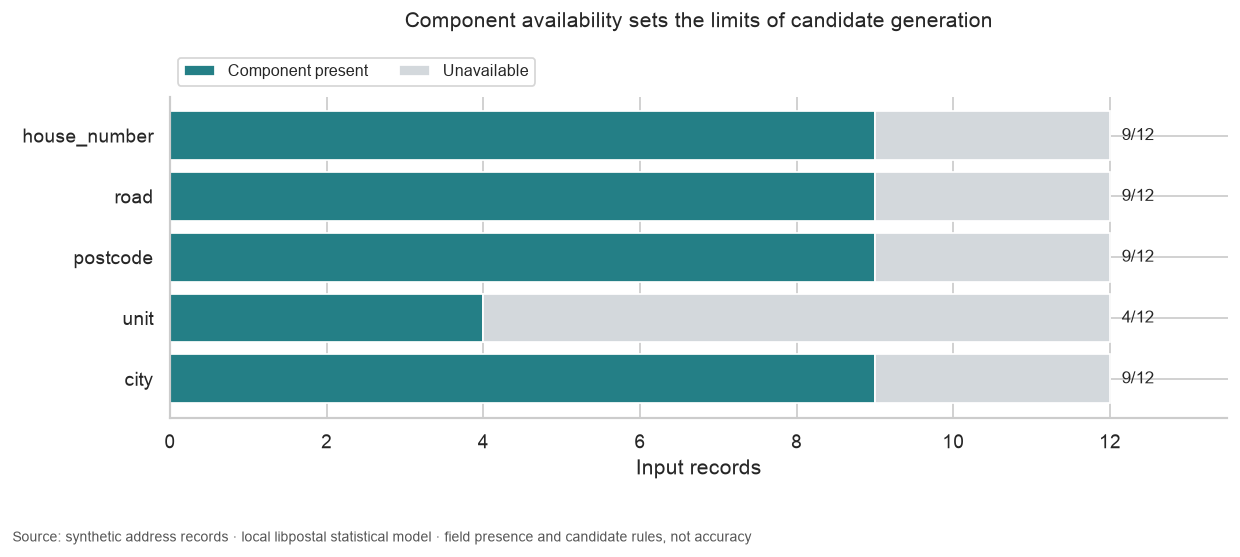

In [8]:
display(coverage)
assert coverage.present.between(0, len(parsed_rows)).all()
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(coverage.component, coverage.present, color="#247f86", label="Component present")
ax.barh(
    coverage.component,
    coverage.records - coverage.present,
    left=coverage.present,
    color="#d3d8dc",
    label="Unavailable",
)
for i, r in enumerate(coverage.itertuples()):
    ax.text(r.records + 0.15, i, f"{r.present}/{r.records}", va="center", fontsize=10)
ax.invert_yaxis()
ax.set(
    xlim=(0, len(parsed_rows) + 1.5),
    xlabel="Input records",
    title="Component availability sets the limits of candidate generation",
)
ax.set_title("Component availability sets the limits of candidate generation", pad=40)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, fontsize=9)
finish(fig)

## Normalize building text and unit text separately

A building key needs a nonempty parsed house number, road and postcode. Country context must also be present. We normalize house-number-plus-road text with libpostal, and remove postcode whitespace only for comparison within the same source country. These choices define this example's candidate rule; they are not a universal address identifier.

Keep unit expansions separate. Missing components do not become empty strings that could accidentally match one another. Multiple expansions are alternatives, not confidence scores, and their count is not a measure of ambiguity probability.

In [9]:
%%sql
CREATE TABLE keyed AS
SELECT *,regexp_replace(lower(postcode),'\s+','','g') AS postcode_key,
 postal.main.expand_address(house_number||' '||road) AS building_forms,
 postal.main.expand_address(unit) AS unit_forms,
 country_code IS NOT NULL AND nullif(trim(house_number),'') IS NOT NULL
 AND nullif(trim(road),'') IS NOT NULL AND nullif(trim(postcode),'') IS NOT NULL AS key_available
FROM components;
CREATE TABLE building_candidates AS
SELECT a.record_id AS left_id,b.record_id AS right_id,a.country_code,a.postcode_key,
 a.unit AS left_unit,b.unit AS right_unit,
 list_intersect(a.building_forms,b.building_forms) AS shared_building_forms,
 CASE WHEN a.unit IS NULL OR b.unit IS NULL THEN 'Unit missing'
      WHEN list_has_any(a.unit_forms,b.unit_forms) THEN 'Unit-form overlap'
      ELSE 'No unit-form overlap' END AS unit_evidence,
 CASE WHEN {{REQUIRE_UNIT_MATCH}}
      THEN a.unit IS NOT NULL AND b.unit IS NOT NULL
           AND coalesce(list_has_any(a.unit_forms,b.unit_forms),false)
      ELSE true END AS retained
FROM keyed a JOIN keyed b
 ON a.record_id<b.record_id AND a.country_code=b.country_code
 AND a.postcode_key=b.postcode_key AND a.key_available AND b.key_available
 AND list_has_any(a.building_forms,b.building_forms);

,Count


In [10]:
%%sql pairs <<
SELECT left_id,right_id,country_code,postcode_key,left_unit,right_unit,
 shared_building_forms,unit_evidence,retained
FROM building_candidates ORDER BY left_id,right_id;

In [11]:
display(pairs)
eligible = con.execute("SELECT count(*) FROM keyed WHERE key_available").fetchone()[0]
assert len(pairs) <= eligible * (eligible - 1) // 2
assert not pairs.duplicated(["left_id", "right_id"]).any()
assert all(pairs.left_id < pairs.right_id)
assert (
    con.execute("SELECT count(*) FROM building_candidates WHERE len(shared_building_forms)=0").fetchone()[0]
    == 0
)
retained = int(pairs.retained.sum())
if REQUIRE_UNIT_MATCH:
    assert pairs.loc[pairs.retained, "unit_evidence"].eq("Unit-form overlap").all()
else:
    assert retained == len(pairs)
prose(
    f"**{eligible} of {len(parsed_rows)} records** have the required building-key components. They produce **{len(pairs)} unordered building candidates**; the retained count is **{retained}** with `REQUIRE_UNIT_MATCH={REQUIRE_UNIT_MATCH}`. **{int(pairs.unit_evidence.eq('Unit missing').sum())} pairs lack a unit on at least one side**. Withholding those pairs avoids treating missing information as agreement, but can omit legitimate unitless addresses."
)

,left_id,right_id,country_code,postcode_key,left_unit,right_unit,shared_building_forms,unit_evidence,retained
0,DE01,DE02,DE,80331,None,None,"[5 hauptstrasse, 5 haupt strasse]",Unit missing,False
1,GB01,GB02,GB,sw1a2aa,None,None,[10 downing street],Unit missing,False
2,US01,US02,US,10128,apt 5b,apartment 5b,"[120 east 96th street, 120 east 96 street]",Unit-form overlap,True
3,US01,US03,US,10128,apt 5b,apt 5c,"[120 east 96th saint, 120 east 96th street, 12...",No unit-form overlap,False
4,US01,US04,US,10128,apt 5b,None,"[120 east 96th saint, 120 east 96th street, 12...",Unit missing,False
5,US02,US03,US,10128,apartment 5b,apt 5c,"[120 east 96th street, 120 east 96 street]",No unit-form overlap,False
6,US02,US04,US,10128,apartment 5b,None,"[120 east 96th street, 120 east 96 street]",Unit missing,False
7,US03,US04,US,10128,apt 5c,None,"[120 east 96th saint, 120 east 96th street, 12...",Unit missing,False


**9 of 12 records** have the required building-key components. They produce **8 unordered building candidates**; the retained count is **1** with `REQUIRE_UNIT_MATCH=True`. **5 pairs lack a unit on at least one side**. Withholding those pairs avoids treating missing information as agreement, but can omit legitimate unitless addresses.

## Show what the policy retains and withholds

The population is the same set of building candidates in both runs. The following counts divide it by available unit evidence and apply only the visible policy. A retained pair still needs review of the raw records, source context and the intended entity; this pipeline has no evidence about residents, deliverability or whether a unit is required.

In [12]:
%%sql
CREATE TABLE decision_counts AS
SELECT unit_evidence,count(*) FILTER (WHERE retained) AS retained_pairs,
 count(*) FILTER (WHERE NOT retained) AS withheld_pairs
FROM building_candidates GROUP BY unit_evidence;

,Count


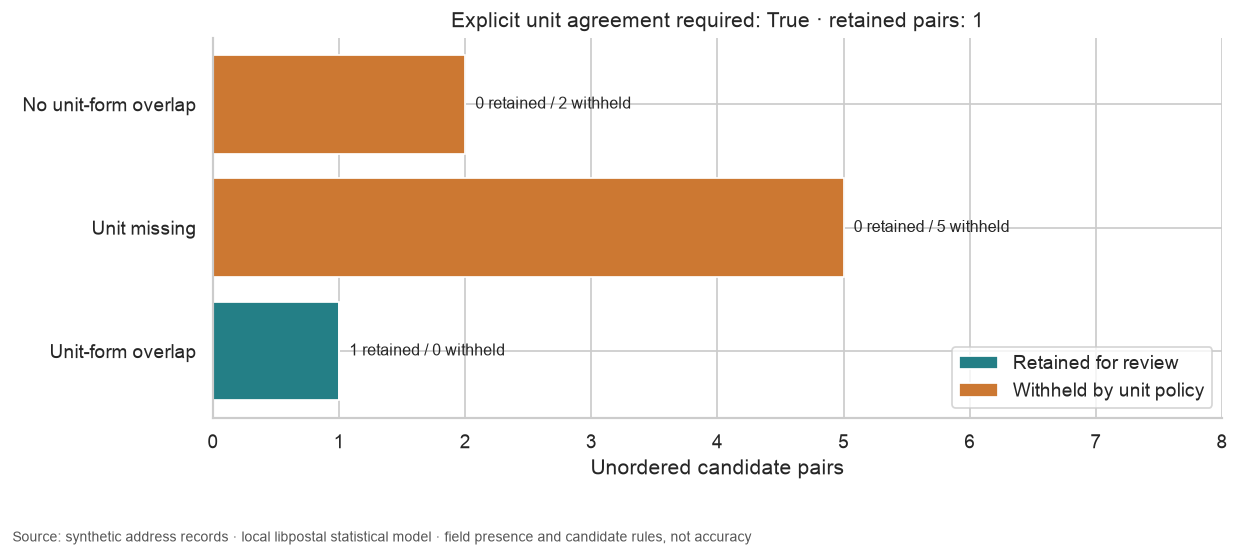

In [13]:
decisions = con.execute("SELECT * FROM decision_counts ORDER BY unit_evidence").df()
assert int(decisions.retained_pairs.sum() + decisions.withheld_pairs.sum()) == len(pairs)
if len(decisions):
    fig, ax = plt.subplots(figsize=(10, 4.6))
    ax.barh(decisions.unit_evidence, decisions.retained_pairs, color="#247f86", label="Retained for review")
    ax.barh(
        decisions.unit_evidence,
        decisions.withheld_pairs,
        left=decisions.retained_pairs,
        color="#cc7832",
        label="Withheld by unit policy",
    )
    for i, r in enumerate(decisions.itertuples()):
        ax.text(
            r.retained_pairs + r.withheld_pairs + 0.08,
            i,
            f"{r.retained_pairs} retained / {r.withheld_pairs} withheld",
            va="center",
            fontsize=9,
        )
    ax.invert_yaxis()
    ax.set(
        xlim=(0, max(decisions.retained_pairs + decisions.withheld_pairs) + 3),
        xlabel="Unordered candidate pairs",
        title=f"Explicit unit agreement required: {REQUIRE_UNIT_MATCH} · retained pairs: {retained}",
    )
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.legend(loc="lower right")
    finish(fig)
else:
    prose("**Candidate chart omitted:** the parsed and normalized inputs produced no building candidates.")

## Experiment: relax only the unit requirement

Change `REQUIRE_UNIT_MATCH` from **True to False** in a separate executed copy. The input and parsed-field fingerprints, component coverage, building expansions and building-candidate population should remain identical. Compare retained counts and the changed policy colors, then inspect the newly retained pairs' unit evidence. Restore **True** afterwards.

More candidates mean broader review coverage, not a demonstrated improvement in duplicate detection. Conversely, the strict policy can discard valid pairs when units are absent or parsed differently. A real evaluation needs representative labeled pairs and the cost of each error; this small synthetic example provides neither.

In [14]:
con.close()
native.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)